In [4]:
import pandas as pd         # Lesen von Daten aus Excel
import seaborn as sea       # Visualisierung
import matplotlib.pyplot as plt
import numpy as np

# um Warnungen zu ignorieren (auf eigene Gefahr!)
import warnings
warnings.filterwarnings("ignore")

In [5]:
# Eilesen eines Datensatzes & Filtern
netflix = pd.read_excel('./data/all-weeks-countries.xlsx')
display(netflix.head(3)) # Zeigt die ersten Zeilen an
display(netflix.tail(5)) # Zeigt die letzen Zeilen an
print('Größe des Datensatzes: {}'.format(netflix.shape))
display(netflix.info()) # allgemeine Infos zum Datensatz
display(netflix.describe()) # statistische Kennzahlen zum Datensatz
# Reduzieren des Datensatz auf 2024-08-18
netflix_lastweek = netflix[netflix['week']=='2024-08-18']
# Reduzieren des Datensatz auf Filme und weekly_rank == 1
netflix_top = netflix_lastweek[(netflix_lastweek['category'] == 'Films')
                               & (netflix_lastweek['weekly_rank'] == 1)]
netflix.value_counts('Price') # Zählt wie oft "Price" vorkommt
netflix = netflix.drop(index=10472) # Löscht einen Datensatz an index
# Entfernt duplikate und behät den ersten
netflix = netflix.drop_duplicates(keep='first')


FileNotFoundError: [Errno 2] No such file or directory: './data/all-weeks-countries.xlsx'

In [1]:
google_free.value_counts('Price') # Zählt wie oft "Price" vorkommt
google = google.drop(index=10472) # Löscht einen Datensatz an index
# Entfernt duplikate und behät den ersten
google = google.drop_duplicates(keep='first')

NameError: name 'google_free' is not defined

In [ ]:
# Modus = der am häufigsten vorkomende Wert eines Merkmals
for col in ['Category', 'Content Rating', 'Genres']:
    print(col)
    print('Modus: {}\n'.format(netflix[col].mode().values))

In [ ]:
# Grafiken darstellen
fig, ax =plt.subplots(1,1,figsize=(10,6)) #plt.subplots(zeilen, spalten, größe in Zoll)
cax = ax
# Absolute Häufigkeit
sea.countplot( data=google, y='Category', order=google.value_counts('Category').index)
# Relative Häufigkeit
sea.histplot(data=google,x='Content Rating',stat='percent', discrete=True, shrink=0.8)
fig.autofmt_xdate() # Formatiert die x Achse
# Aggregierte Daten (Nur Top 20 Geners
counts = google.value_counts('Genres')
sea.barplot(y=counts.index[:20], x=counts.values[:20])
print(len(counts)) # Anzahl Merkmalsausprägungen



In [ ]:
# Kreuztabelle für die Merkmale Content Rating und Type
ktab = pd.crosstab(google['Type'], google['Content Rating'], margins=True, margins_name='all')
display(ktab)
# Bedingte Häufigkeiten p(Paid | Everyone)
print('P(Paid | Everyone): {0:.4f}'.format(662/8382))


In [ ]:
data = pd.read_csv('./data/Advertising.csv', index_col=0)


In [2]:
# Kumulativer Häufigkeitsplot min Budget der 30% mit dem höchsten Budget
fig, axs = plt.subplots(ncols=2, nrows=1, figsize=(12,4))
cax = axs[0]
sea.ecdfplot(data=data, x='TV', ax=cax, stat='percent')
# Newspaper als Boxplot & Wie viele Ausreißer gibt es?
cax = axs[1]
sea.boxplot(data=data, x='newspaper', ax=cax)
plt.show()
print('70%-Quantil von TV (minimales Budget der 30% der Kampagnen mit dem höchsten TV-Budget): {0:.4f}'
      .format(np.quantile(data['TV'], 0.7)))
# Bestimmung von unteren und oberen Quartil für newspaper
quarts = np.quantile(data['newspaper'], [0.25, 0.75])
outlier_bound = quarts[1] + 1.5*(quarts[1] - quarts[0])
print('Ausreißer')
print(data['newspaper'][data['newspaper'] > outlier_bound])

NameError: name 'data' is not defined

In [ ]:
# Kennzahlen der Merkmale
tmp = data.describe()
report = pd.DataFrame(index = data.columns, columns = ['mean', 'std', 'median', 'iqr'])
for col in data.columns:
    report.loc[col] = [tmp.loc['mean',col], tmp.loc['std', col], tmp.loc['50%', col], tmp.loc['75%', col]-tmp.loc['25%', col]]

display(report)



In [3]:
display(data.corr(method='pearson')) # Pearson korrelationsmatrix
sea.pairplot(data=data, diag_kind='hist', height=2, corner=True)
plt.show()


NameError: name 'data' is not defined

In [ ]:
from scipy.stats import hypergeom

# 27 Teile, 2 Defekt, 3 Stickprobe
[M, n, N] = [27, 2, 3]
rv = hypergeom(M, n, N)
x = np.arange(0, 3)
# Bestimme Wahrscheinlichkeiten
pmf_defStift = rv.pmf(x)
print(pmf_defStift) # Wahrscheinlichkeiten
rv.pmf(1) # 1 Defekt
rv.pmf(1) + rv.pmf(2) # 2 Defekt
rv.pmf(0) # Keiner Defekt


In [11]:
spam = 0.2
no_spam = 1 - spam

gewinn_spam = 0.19
keinspam_gewinn = 0.01

msg_gewinn_spam = (gewinn_spam*spam)/((gewinn_spam*spam) + (no_spam*keinspam_gewinn))
print(msg_gewinn_spam)

0.8260869565217391


In [ ]:
from scipy.stats import binom

# Wahrscheinlichkeit, dass in einer Stichprobe von 500
# Einheiten min 2, max 5 feherhafte Teile gefunden
[n, p] = [500, 0.04] # 500 Teile, 4% Defekt
rv = binom(n, p)
x = np.arange(2, 6) # 6 exclusive!
print(x)
res = sum(rv.pmf(x))
print('Die Wahrscheinlichkeit beträgt {:.4f}%'.format(res*100))

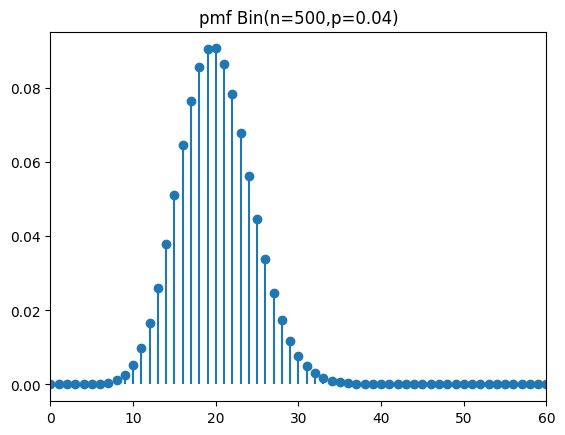

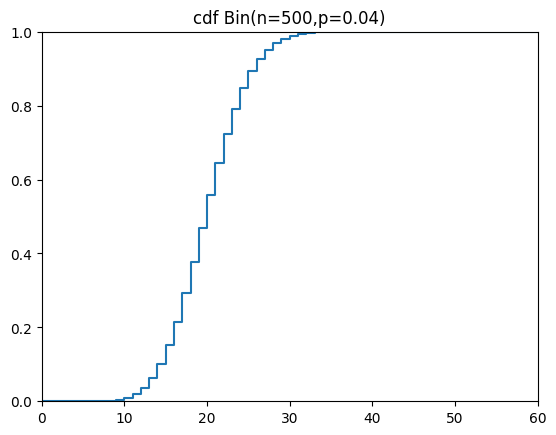

In [15]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import binom

p = 0.04
n = 500  # für b)–e); für a) beliebig wählbar

k = np.arange(0, n+1)
pmf = binom.pmf(k, n, p)
cdf = binom.cdf(k, n, p)

plt.figure()
plt.stem(k, pmf, basefmt=" ")
plt.xlim(0, 60)
plt.title("pmf Bin(n=500,p=0.04)")
plt.show()

plt.figure()
plt.step(k, cdf, where="post")
plt.xlim(0, 60); plt.ylim(0, 1)
plt.title("cdf Bin(n=500,p=0.04)")
plt.show()


In [ ]:
import seaborn as sn

# Density Plot Visualisierung
penguins = pd.read_excel('./data/penguinsSmall.xlsx', index_col=0)
Adelie = penguins[penguins.Species == "Adelie"] # Filter
sn.kdeplot(data=Adelie, x="Flipper Length (mm)", fill=True)

In [ ]:
from scipy.stats import t
# Konfidenzintervalle
penguins = pd.read_excel('./data/penguinsSmall.xlsx', index_col=0)
Adelie_Flipper_Length = penguins.loc[penguins['Species'] == "Adelie", ['Flipper Length (mm)']]
mean_Adelie = Adelie_Flipper_Length.mean()[0]
std_Adelie = np.std(Adelie_Flipper_Length, ddof = 1)[0]
alpha = 0.05 # t-statistik
n = Adelie_Flipper_Length.count()[0]
t_stats = round(t.ppf(1-alpha/2 , n-1), 3)
LB = round(mean_Adelie - t_stats*std_Adelie/np.sqrt(n) , 2)
UB = round(mean_Adelie + t_stats*std_Adelie/np.sqrt(n) , 2)
print('Adelie: Konfidenzintervall für den Erwartungswert: [{0} ; {1}]'.format(LB, UB))


In [ ]:
import pingouin as pg ## für t-Test
# Hypothenesntest
Adelie_Flipper_Length_array = np.array(Adelie_Flipper_Length.iloc[:,0])
result = pg.ttest(Adelie_Flipper_Length_array, 190)
result # p-val < 0.05 -> H0 verwerfen; CI95% -> Drin oder draussen


In [ ]:
import numpy as np
from scipy.stats import t, norm

def mean_test(x, mu0, alpha=0.05, sigma=None):
    x = np.asarray(x, float); n = x.size
    xbar = x.mean()
    if sigma is None:  # t-Test (σ unbekannt)
        s = x.std(ddof=1)
        stat = (xbar-mu0)/(s/np.sqrt(n))
        crit = t.ppf(1-alpha/2, n-1)
    else:             # z-Test (σ bekannt)
        stat = (xbar-mu0)/(sigma/np.sqrt(n))
        crit = norm.ppf(1-alpha/2)
    return stat, crit, (abs(stat) > crit)
# Beispiel:
# stat, crit, reject = mean_test(x, mu0=5)           # t-Test
# stat, crit, reject = mean_test(x, mu0=5, sigma=0.1) # z-Test
